# 📤 Import & Install Libraries

In [196]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
from sklearn.model_selection import train_test_split

# 💾 Prepare the Data

In [197]:
df = pd.read_csv(r"data/apartments.csv") #Loading the dataset via pandas module
area = df[["area_m2"]].values
price = df.price_thousands_pln.values

In [198]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 10 entries, 0 to 9
Data columns (total 2 columns):
 #   Column               Non-Null Count  Dtype
---  ------               --------------  -----
 0   area_m2              10 non-null     int64
 1   price_thousands_pln  10 non-null     int64
dtypes: int64(2)
memory usage: 292.0 bytes


In [199]:
print(df.head(5)) #First 5 rows from the dataset

   area_m2  price_thousands_pln
0       35                  310
1       42                  355
2       50                  395
3       57                  430
4       65                  470


In [200]:
df.describe() #Basic descriptive statistics about the data

,area_m2,price_thousands_pln
count,10.000000,10.000000
mean,71.100000,509.000000
std,26.863647,146.055545
min,35.000000,310.000000
25%,51.750000,403.750000
50%,68.500000,492.500000
75%,87.500000,601.250000
max,120.000000,770.000000


In [201]:
df.corr()

,area_m2,price_thousands_pln
area_m2,1.000000,0.999681
price_thousands_pln,0.999681,1.000000


<Axes: >

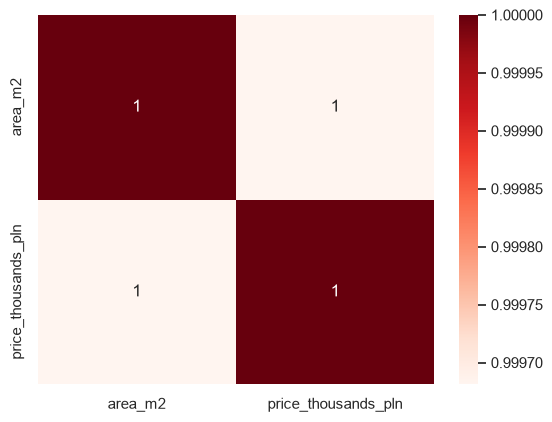

In [202]:
sns.heatmap(df.corr(), annot=True, cmap="Reds")  #If area increases price does increase as well

# What problem are we trying to solve?

We are trying to predict price (thousands of PLN) from floor area by using simple linear regression algorithm.

# Exploratory Data Analysis

As seen from the data, area and price has positive relationship, hence, makes the slop positive

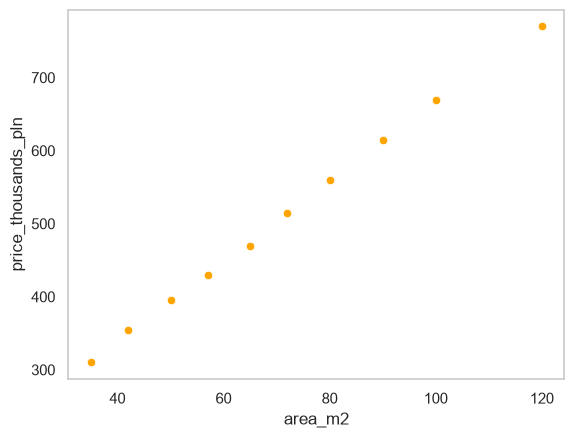

In [203]:
sns.scatterplot(data=df, x="area_m2", y="price_thousands_pln", color="orange") #Dependent price according to independent area
sns.set_theme(style="whitegrid")
plt.grid()
plt.show()


In [204]:
model = LinearRegression()
model.fit(area, price)
b0 = model.intercept_
b1 = model.coef_[0]
print("Coefficient b1:", b1)
print("Intercept b0:", b0)

Coefficient b1: 5.435187608739161
Intercept b0: 122.55816101864565



**Linear Regression Formula:**
x is area, b1 is Coefficient (slope), b0 is intercept, y is the price
            $$\hat{y} = b_0 + b_1 x$$

In [205]:
sample = np.array([[40],[60],[80],[100]])   #2D array with shape (4,1)
pred = model.predict(sample)

for m2, p in zip(sample.flatten(), pred): #Flattens the multidimensional array into one-dimensional array to match sample with prediction
    print(f"Predicted price for {m2} m²: {p:.1f} thousand PLN")


Predicted price for 40 m²: 340.0 thousand PLN
Predicted price for 60 m²: 448.7 thousand PLN
Predicted price for 80 m²: 557.4 thousand PLN
Predicted price for 100 m²: 666.1 thousand PLN


#   ✔️Goodness-of-Fit (The higher the better)
*   R2 tells us how well a regression line predicts the actual values. It is calculated via comparing the actual values "price" to estimated values "model.predict(area)"     $$R^2 = \frac{SS_{reg}}{SS_{tot}} = \frac{\sum_{i=1}^{n}(\hat{y}_i - \bar{y})^2}{\sum_{i=1}^{n}(y_i - \bar{y})^2}$$

In [206]:
price_predict = model.predict(area)
r2 = r2_score(price,price_predict)
print(f"R2 value is: {r2}")

R2 value is: 0.9993622468675517


#   ✔Error Metrics (The lower the better)

*   Standard Error Estimate calculates how good our estimation fits. Found via comparison in between the actual values to estimated values.
                            $$s_e = \sqrt{\frac{\sum_{i=1}^{n}(y_i - \hat{y}_i)^2}{n-k-1}}$$

*   **MAE** (mean absolute error)

$$\text{MAE} = \frac{1}{n}\sum_{i=1}^{n}\left|y_i - \hat{y}_i\right|$$

* **MSE** (mean squared error)

$$\text{MSE} = \frac{1}{n}\sum_{i=1}^{n}(y_i - \hat{y}_i)^2$$

* **RMSE** (root mean squared error)

$$\text{RMSE} = \sqrt{\frac{1}{n}\sum_{i=1}^{n}(y_i - \hat{y}_i)^2}$$

In [207]:
MAE = mean_absolute_error(price,price_predict)
MSE = mean_squared_error(price,price_predict)
RMSE = np.sqrt(MSE)
print(f"Mean absolute error is {MAE}")
print(f"Mean squared error is {MSE}")
print(f"Root mean squared error is {RMSE}")

Mean absolute error is 3.155922339066035
Mean squared error is 12.244222389875123
Root mean squared error is 3.499174529782006


#   Linear Regression Line

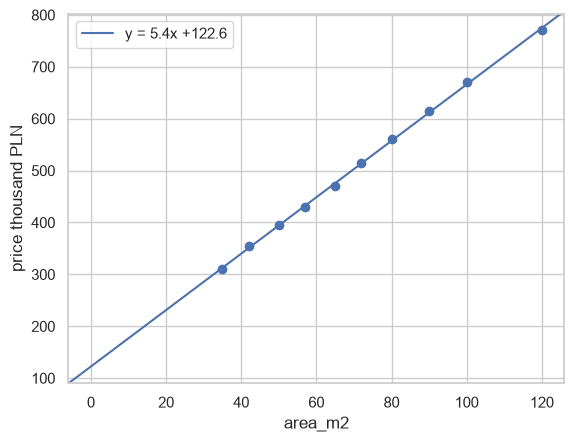

In [208]:
plt.scatter(area,price)
plt.axline(xy1=(0, b0), slope=b1, label=f'y = {b1:.1f}x +{b0:.1f}' )
plt.xlabel("area_m2")
plt.ylabel("price thousand PLN")
plt.legend()
plt.savefig("regression.png")
plt.show()

#   Adding New Data Column
A fixed base price (122.6) is spread over more m² in bigger flats, so the average price per m² falls toward the constant 5.4 cost of each extra m². Between area and price per m² the relationship is negative (as one goes up, the other goes down).

In [209]:
df["price_per_m2"] = df["price_thousands_pln"] / df["area_m2"]
print(df[["area_m2", "price_per_m2"]])

   area_m2  price_per_m2
0       35      8.857143
1       42      8.452381
2       50      7.900000
3       57      7.543860
4       65      7.230769
5       72      7.152778
6       80      7.000000
7       90      6.833333
8      100      6.700000
9      120      6.416667


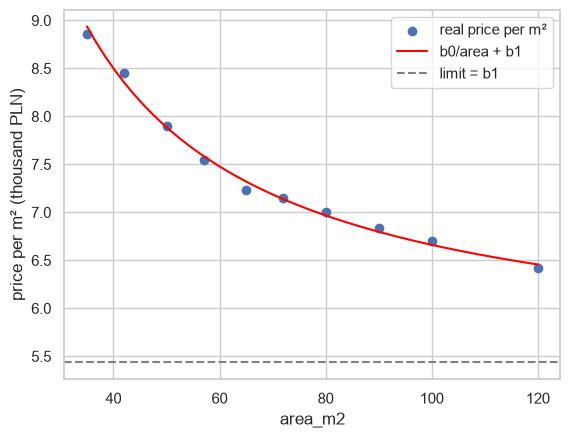

In [210]:
x_curve = np.linspace(35, 120)     # smooth range of areas
y_curve = b0 / x_curve + b1             # the formula: b0/area + b1

plt.scatter(area, df["price_per_m2"], label="real price per m²")
plt.plot(x_curve, y_curve, color="red", label="b0/area + b1")
plt.axhline(b1, color="gray", linestyle="--", label="limit = b1")
plt.xlabel("area_m2")
plt.ylabel("price per m² (thousand PLN)")
plt.legend()
plt.show()

# Adding Another Column to Our Data For Polynomial Regression


In [211]:
df["area_m2_sq"] = df["area_m2"] ** 2
area_m2_sq = df[["area_m2_sq"]].values
print(area_m2_sq)

[[ 1225]
 [ 1764]
 [ 2500]
 [ 3249]
 [ 4225]
 [ 5184]
 [ 6400]
 [ 8100]
 [10000]
 [14400]]


In [212]:
X_polynomial = df[["area_m2", "area_m2_sq"]].values
model_polynomial = LinearRegression()
model_polynomial.fit(X_polynomial, price)
polynomial_predict = model_polynomial.predict(X_polynomial)

b0_polynomial = model_polynomial.intercept_
b1_polynomial = model_polynomial.coef_[0]
b2_polynomial = model_polynomial.coef_[1]
print("Coefficient (b1, b2):", model_polynomial.coef_)
print("Intercept b0:", b0_polynomial)


Coefficient (b1, b2): [ 5.68958423e+00 -1.67237033e-03]
Intercept b0: 114.01093192037354


In [213]:
for m2, p in zip(area.flatten(), polynomial_predict): #Flattens the multidimensional array into one-dimensional array to match sample with prediction
    print(f"Polynomial prediction price for {m2} m²: {p:.1f} thousand PLN")


Polynomial prediction price for 35 m²: 311.1 thousand PLN
Polynomial prediction price for 42 m²: 350.0 thousand PLN
Polynomial prediction price for 50 m²: 394.3 thousand PLN
Polynomial prediction price for 57 m²: 432.9 thousand PLN
Polynomial prediction price for 65 m²: 476.8 thousand PLN
Polynomial prediction price for 72 m²: 515.0 thousand PLN
Polynomial prediction price for 80 m²: 558.5 thousand PLN
Polynomial prediction price for 90 m²: 612.5 thousand PLN
Polynomial prediction price for 100 m²: 666.2 thousand PLN
Polynomial prediction price for 120 m²: 772.7 thousand PLN


In [214]:
for m2, p in zip(sample, polynomial_predict): #Flattens the multidimensional array into one-dimensional array to match sample with prediction
    print(f"Polynomial prediction price for {m2} m²: {p:.1f} thousand PLN")


Polynomial prediction price for [40] m²: 311.1 thousand PLN
Polynomial prediction price for [60] m²: 350.0 thousand PLN
Polynomial prediction price for [80] m²: 394.3 thousand PLN
Polynomial prediction price for [100] m²: 432.9 thousand PLN


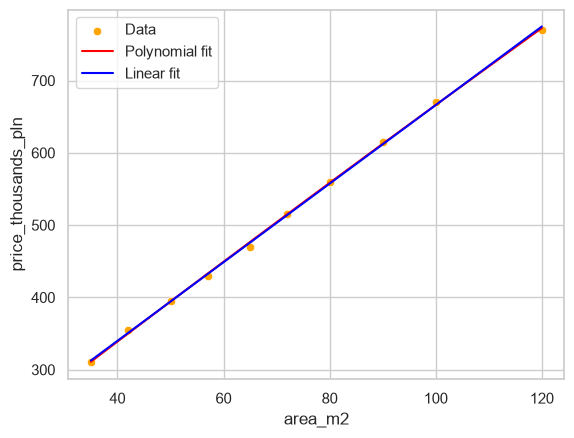

In [215]:
sns.scatterplot(data=df, x="area_m2", y="price_thousands_pln", color="orange", label="Data")
plt.plot(df["area_m2"], polynomial_predict, color="red", label="Polynomial fit")
plt.plot(df["area_m2"], price_predict, color="blue", label="Linear fit")
plt.legend()
plt.show()

In [216]:
MAE_polynomial = mean_absolute_error(price,polynomial_predict)
MSE_polynomial = mean_squared_error(price,polynomial_predict)
RMSE_polynomial = np.sqrt(MSE_polynomial)
print(f"Mean absolute error for polynomial regression {MAE_polynomial}, for linear regression {MAE}")
print(f"Mean squared error for polynomial regression {MSE_polynomial}, for linear regression {MSE}")
print(f"Root mean squared error for polynomial regression {RMSE_polynomial}, for linear regression {RMSE}")


Mean absolute error for polynomial regression 2.6856956989484786, for linear regression 3.155922339066035
Mean squared error for polynomial regression 11.028521116058007, for linear regression 12.244222389875123
Root mean squared error for polynomial regression 3.3209217268791518, for linear regression 3.499174529782006


# Practice data that fits polynomial regression


In [217]:
df2 = pd.read_csv(r"data/practice_data.csv") #Loading the dataset via pandas module
df2_area = df2[["area_m2"]].values
df2_price = df2.price_thousands_pln.values

In [218]:
df2.info()

<class 'pandas.DataFrame'>
RangeIndex: 10 entries, 0 to 9
Data columns (total 2 columns):
 #   Column               Non-Null Count  Dtype
---  ------               --------------  -----
 0   area_m2              10 non-null     int64
 1   price_thousands_pln  10 non-null     int64
dtypes: int64(2)
memory usage: 292.0 bytes


In [219]:
print(df2.head(5))

   area_m2  price_thousands_pln
0       30                  264
1       40                  327
2       50                  402
3       60                  488
4       70                  589


In [220]:
df2.describe()

,area_m2,price_thousands_pln
count,10.000000,10.000000
mean,75.000000,688.400000
std,30.276504,335.760563
min,30.000000,264.000000
25%,52.500000,423.500000
50%,75.000000,641.500000
75%,97.500000,917.500000
max,120.000000,1254.000000


In [221]:
df2.corr()

,area_m2,price_thousands_pln
area_m2,1.000000,0.991027
price_thousands_pln,0.991027,1.000000


<Axes: >

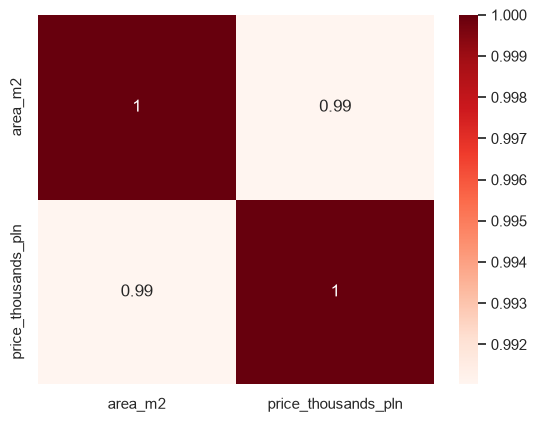

In [222]:
sns.heatmap(df2.corr(),annot=True, cmap="Reds")

In [223]:
model_df2 = LinearRegression()
model_df2.fit(df2_area,df2_price)
df2_price_predict = model_df2.predict(df2_area)
b0_df2 = model_df2.intercept_
b1_df2 = model_df2.coef_[0]
print("Coefficient b1:", model_df2.coef_[0])
print("Intercept b0:", model_df2.intercept_)

Coefficient b1: 10.990303030303032
Intercept b0: -135.8727272727274


In [224]:
sample_df2 = np.array([[40],[60],[80],[100]])   #2D array with shape (4,1)
pred_df2 = model_df2.predict(sample_df2)

for m2, p in zip(sample_df2.flatten(), pred_df2): #Flattens the multidimensional array into one-dimensional array to match sample with prediction
    print(f"Predicted price for {m2} m²: {p:.1f} thousand PLN")

Predicted price for 40 m²: 303.7 thousand PLN
Predicted price for 60 m²: 523.5 thousand PLN
Predicted price for 80 m²: 743.4 thousand PLN
Predicted price for 100 m²: 963.2 thousand PLN


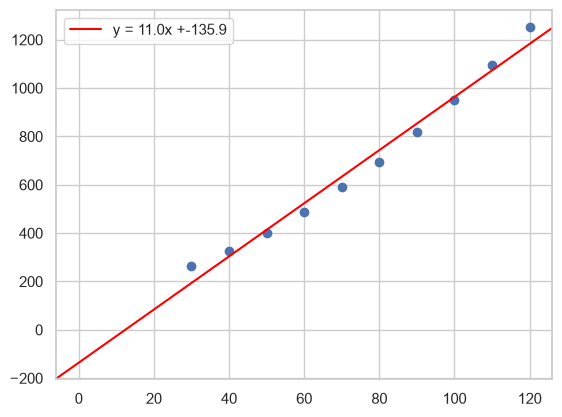

In [225]:
x_curve = np.linspace(0,130,10)

plt.scatter(df2_area,df2_price)
plt.axline(xy1=(0, b0_df2), slope=b1_df2, label=f'y = {b1_df2:.1f}x +{b0_df2:.1f}' , color="red")
plt.legend()
plt.show()

In [226]:
df2_MAE = mean_absolute_error(df2_price,df2_price_predict)
df2_MSE = mean_squared_error(df2_price,df2_price_predict)
df2_RMSE = np.sqrt(df2_MSE)
df2_r2 = r2_score(df2_price,df2_price_predict)
print(f"Mean absolute error is {df2_MAE}")
print(f"Mean squared error is {df2_MSE}")
print(f"Root mean squared error is {df2_RMSE}")
print(f"R2 value is: {df2_r2}")

Mean absolute error is 37.480000000000004
Mean squared error is 1812.5624242424249
Root mean squared error is 42.57419904405043
R2 value is: 0.9821354905731622


In [227]:
df2["price_per_m2"] = df2["price_thousands_pln"] / df2["area_m2"]
print(df2[["area_m2","price_per_m2"]])

   area_m2  price_per_m2
0       30      8.800000
1       40      8.175000
2       50      8.040000
3       60      8.133333
4       70      8.414286
5       80      8.675000
6       90      9.111111
7      100      9.500000
8      110      9.963636
9      120     10.450000


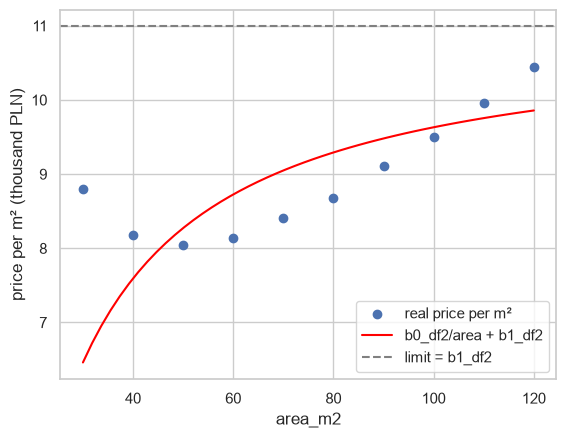

In [228]:
x_curve = np.linspace(30, 120)     # smooth range of areas
y_curve = b0_df2 / x_curve + b1_df2             # the formula: b0_df2/area + b1_df2

plt.scatter(df2_area, df2["price_per_m2"], label="real price per m²")
plt.plot(x_curve, y_curve, color="red", label="b0_df2/area + b1_df2")
plt.axhline(b1_df2, color="gray", linestyle="--", label="limit = b1_df2")
plt.xlabel("area_m2")
plt.ylabel("price per m² (thousand PLN)")
plt.legend()
plt.show()

In [229]:
df2["area_m2_sq"] = df2["area_m2"] ** 2
df2_area_m2_sq = df2[["area_m2_sq"]].values
print(df2_area_m2_sq)

[[  900]
 [ 1600]
 [ 2500]
 [ 3600]
 [ 4900]
 [ 6400]
 [ 8100]
 [10000]
 [12100]
 [14400]]


In [232]:
df2_X_polynomial = df2[["area_m2_sq", "area_m2"]].values
model2_polynomial = LinearRegression()
model2_polynomial.fit(df2_X_polynomial,df2_price)
polynomial2_predict = model2_polynomial.predict(df2_X_polynomial)

df2_b0_polynomial = model2_polynomial.intercept_
df2_b1_polynomial = model2_polynomial.coef_[0]
df2_b2_polynomial = model2_polynomial.coef_[1]
print("Coefficient (b1, b2):", model2_polynomial.coef_)
print("Intercept b0:", df2_b0_polynomial)

Coefficient (b1, b2): [0.05856061 2.20621212]
Intercept b0: 145.21818181818128


In [236]:
for m2, p in zip(df2_area.flatten(), polynomial2_predict): #Flattens the multidimensional array into one-dimensional array to match sample with prediction
    print(f"Polynomial prediction price for {m2} m²: {p:.1f} thousand PLN")


Polynomial prediction price for 30 m²: 264.1 thousand PLN
Polynomial prediction price for 40 m²: 327.2 thousand PLN
Polynomial prediction price for 50 m²: 401.9 thousand PLN
Polynomial prediction price for 60 m²: 488.4 thousand PLN
Polynomial prediction price for 70 m²: 586.6 thousand PLN
Polynomial prediction price for 80 m²: 696.5 thousand PLN
Polynomial prediction price for 90 m²: 818.1 thousand PLN
Polynomial prediction price for 100 m²: 951.4 thousand PLN
Polynomial prediction price for 110 m²: 1096.5 thousand PLN
Polynomial prediction price for 120 m²: 1253.2 thousand PLN


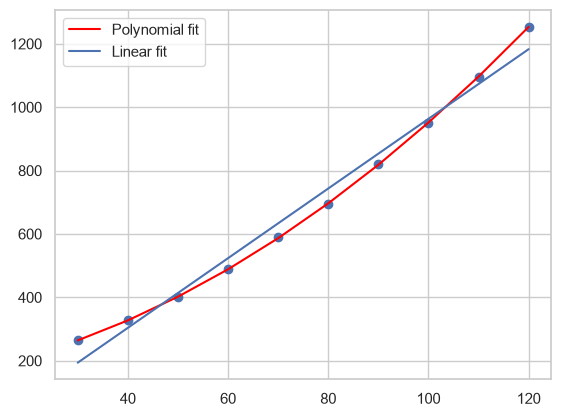

In [240]:
plt.scatter(df2_area, df2_price)
plt.plot(df2["area_m2"], polynomial2_predict, color="red", label="Polynomial fit")
plt.plot(df2["area_m2"], df2_price_predict, label="Linear fit" )
plt.legend()
plt.show()


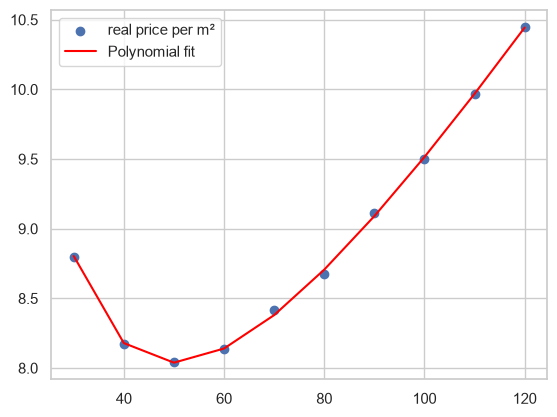

In [247]:
plt.scatter(df2_area, df2["price_per_m2"], label="real price per m²")
plt.plot(df2["area_m2"], polynomial2_predict / df2["area_m2"], color="red", label="Polynomial fit")
plt.legend()
plt.show()
